<a href="https://colab.research.google.com/github/mehrotragunja/CSET485-AI-Society-Assignment/blob/main/AI_and_Society_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:


import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/adult_data"

print("ZIP exists:", os.path.exists(zip_path))



ZIP exists: False


In [ ]:

import os

for root, dirs, files in os.walk("/"):
    if "archive.zip" in files:
        print("ZIP file location:", os.path.join(root, "archive.zip"))
        break


ZIP file location: /archive.zip


In [ ]:

import zipfile
import os

zip_path = "/archive.zip"
extract_path = "/content/adult_data"

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:", z.namelist())
    z.extractall(extract_path)

print("\nExtraction successful!")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))


Files inside ZIP: ['adult.csv']

Extraction successful!
/content/adult_data/adult.csv


In [ ]:

import pandas as pd

df = pd.read_csv("/content/adult_data/adult.csv")

print("Number of rows and columns:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()

df = df.replace(r"^\s*\?\s*$", pd.NA, regex=True)

print("\nMissing values in each column:")
print(df.isna().sum())


Number of rows and columns: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

Missing values in each column:
age                  0
workclass       

In [ ]:

import pandas as pd

df = df.replace(r"^\s*\?\s*$", pd.NA, regex=True)

print("Missing values before cleaning:")
print(df.isna().sum())

categorical_cols = df.select_dtypes(
    include=["object"]
).columns.tolist()

for col in categorical_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:")
print(df.isna().sum())

print("\nDataset shape after cleaning:", df.shape)


Missing values before cleaning:
age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

Missing values after cleaning:
age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

Dataset shape after cleaning: (32561, 15)


In [ ]:

print(df["income"].value_counts())

df["income_binary"] = (
    df["income"].str.strip() == ">50K"
).astype(int)

print("\nBinary target distribution:")
print(df["income_binary"].value_counts())

print("\nIncome percentages:")
print(
    (df["income_binary"].value_counts(normalize=True) * 100)
    .round(2)
)


income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Binary target distribution:
income_binary
0    24720
1     7841
Name: count, dtype: int64

Income percentages:
income_binary
0    75.92
1    24.08
Name: proportion, dtype: float64


In [ ]:

from sklearn.model_selection import train_test_split

X = df.drop(columns=["income", "income_binary"])
y = df["income_binary"]

categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=86
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))


Categorical columns: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']

Numerical columns: ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']

Training rows: 22792
Testing rows: 9769


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [ ]:

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model_a = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

model_a.fit(X_train, y_train)

linear_predictions = model_a.predict(X_test)

model_b = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

model_b.fit(X_train, y_train)

logistic_probabilities = model_b.predict_proba(X_test)[:, 1]

logistic_predictions = (
    logistic_probabilities >= 0.5
).astype(int)

print("Both models trained successfully!")
print("\nFirst 5 Linear Regression predictions:")
print(linear_predictions[:5])

print("\nFirst 5 Logistic Regression probabilities:")
print(logistic_probabilities[:5])

print("\nLogistic Regression accuracy:",
      round(accuracy_score(y_test, logistic_predictions) * 100, 2), "%")

print("\nClassification report:")
print(classification_report(y_test, logistic_predictions))


Both models trained successfully!

First 5 Linear Regression predictions:
[ 0.25164265 -0.07538617  0.16145903  0.28432388  0.48102726]

First 5 Logistic Regression probabilities:
[0.03935348 0.00295545 0.0756969  0.12444024 0.45209263]

Logistic Regression accuracy: 84.77 %

Classification report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90      7484
           1       0.71      0.60      0.65      2285

    accuracy                           0.85      9769
   macro avg       0.79      0.76      0.77      9769
weighted avg       0.84      0.85      0.84      9769



In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

linear_median = np.median(linear_predictions)
linear_classes = (linear_predictions >= linear_median).astype(int)

logistic_classes = (logistic_probabilities >= 0.5).astype(int)

cm = confusion_matrix(
    linear_classes,
    logistic_classes,
    labels=[0, 1]
)

mismatches = np.sum(linear_classes != logistic_classes)
total = len(y_test)
mismatch_percentage = (mismatches / total) * 100

print("Median Linear Regression prediction:", round(linear_median, 4))
print("\nConfusion Matrix:")
print(pd.DataFrame(
    cm,
    index=["Linear: Low income", "Linear: High income"],
    columns=["Logistic: Low income", "Logistic: High income"]
))

print("\nTotal test cases:", total)
print("Mismatched cases:", mismatches)
print("Mismatch percentage:", round(mismatch_percentage, 2), "%")
print("Agreement percentage:", round(100 - mismatch_percentage, 2), "%")


Median Linear Regression prediction: 0.2257

Confusion Matrix:
                     Logistic: Low income  Logistic: High income
Linear: Low income                   4871                     13
Linear: High income                  2967                   1918

Total test cases: 9769
Mismatched cases: 2980
Mismatch percentage: 30.5 %
Agreement percentage: 69.5 %


In [ ]:
#2.1

import statsmodels.api as sm
import pandas as pd

analysis_df = X_train.copy()
analysis_df["income_binary"] = y_train

print(analysis_df["sex"].value_counts())

predictors = ["education.num", "age", "hours.per.week"]

def fit_subgroup_model(data):
    X_sub = data[predictors].astype(float)
    X_sub = sm.add_constant(X_sub)
    y_sub = data["income_binary"]

    return sm.Logit(y_sub, X_sub).fit(disp=False)

full_model = fit_subgroup_model(analysis_df)

male_df = analysis_df[analysis_df["sex"] == "Male"]
female_df = analysis_df[analysis_df["sex"] == "Female"]

male_model = fit_subgroup_model(male_df)
female_model = fit_subgroup_model(female_df)

results = []

for group, model in [
    ("Full dataset", full_model),
    ("Male", male_model),
    ("Female", female_model)
]:
    ci = model.conf_int().loc["education.num"]

    results.append({
        "Group": group,
        "Education coefficient": model.params["education.num"],
        "95% CI lower": ci.iloc[0],
        "95% CI upper": ci.iloc[1],
        "p-value": model.pvalues["education.num"]
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


sex
Male      15266
Female     7526
Name: count, dtype: int64


,Group,Education coefficient,95% CI lower,95% CI upper,p-value
0,Full dataset,0.3497,0.3345,0.3648,0.0
1,Male,0.3587,0.3414,0.3761,0.0
2,Female,0.3863,0.3502,0.4224,0.0


In [ ]:
#2,1(b)

interaction_df = analysis_df[
    ["education.num", "age", "hours.per.week", "sex", "income_binary"]
].copy()

interaction_df["female"] = (
    interaction_df["sex"] == "Female"
).astype(int)

interaction_df["education_x_female"] = (
    interaction_df["education.num"] * interaction_df["female"]
)

X_interaction = interaction_df[
    ["education.num", "age", "hours.per.week",
     "female", "education_x_female"]
].astype(float)

X_interaction = sm.add_constant(X_interaction)

interaction_model = sm.Logit(
    interaction_df["income_binary"],
    X_interaction
).fit(disp=False)

print(interaction_model.summary())

print("\nEducation × Female interaction coefficient:",
      round(interaction_model.params["education_x_female"], 4))

print("Interaction p-value:",
      interaction_model.pvalues["education_x_female"])


                           Logit Regression Results                           
Dep. Variable:          income_binary   No. Observations:                22792
Model:                          Logit   Df Residuals:                    22786
Method:                           MLE   Df Model:                            5
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                  0.2272
Time:                        11:58:37   Log-Likelihood:                -9782.1
converged:                       True   LL-Null:                       -12658.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -7.9956      0.141    -56.779      0.000      -8.272      -7.720
education.num          0.3555      0.009     40.690      0.000       0.338       0.373
age                 

In [ ]:
#2.2
import statsmodels.api as sm
import pandas as pd
import numpy as np

ovb_df = X_train.copy()
ovb_df["income_binary"] = y_train

full_predictors = [
    "age", "education.num", "hours.per.week",
    "capital.gain", "capital.loss"
]

reduced_predictors = [
    "age", "hours.per.week",
    "capital.gain", "capital.loss"
]

def fit_logit(data, predictors):
    X_model = sm.add_constant(data[predictors].astype(float))
    return sm.Logit(data["income_binary"], X_model).fit(disp=False)

full_ovb = fit_logit(ovb_df, full_predictors)

reduced_ovb = fit_logit(ovb_df, reduced_predictors)

common_predictors = [
    "age", "hours.per.week", "capital.gain", "capital.loss"
]

rows = []

for variable in common_predictors:
    before = full_ovb.params[variable]
    after = reduced_ovb.params[variable]

    percentage_change = (
        abs(after - before) / abs(before) * 100
        if before != 0 else np.nan
    )

    rows.append({
        "Predictor": variable,
        "Full model coefficient": before,
        "Reduced model coefficient": after,
        "Absolute percentage change": percentage_change
    })

ovb_results = pd.DataFrame(rows)
display(ovb_results.round(4))

print("Omitted variable: education.num")


,Predictor,Full model coefficient,Reduced model coefficient,Absolute percentage change
0,age,0.0441,0.0400,9.1947
1,hours.per.week,0.0404,0.0439,8.7592
2,capital.gain,0.0003,0.0003,3.1067
3,capital.loss,0.0007,0.0008,13.0751


Omitted variable: education.num


In [ ]:
#2.3

import numpy as np
import pandas as pd

adversarial_df = X_test.copy().reset_index(drop=True)
adversarial_df["actual"] = np.asarray(y_test)
adversarial_df["probability"] = logistic_probabilities

false_positives = adversarial_df[
    (adversarial_df["probability"] >= 0.75) &
    (adversarial_df["actual"] == 0)
].copy()

false_negatives = adversarial_df[
    (adversarial_df["probability"] <= 0.25) &
    (adversarial_df["actual"] == 1)
].copy()

wrong_cases = pd.concat(
    [false_positives, false_negatives]
).drop_duplicates()

print("High-confidence false positives:", len(false_positives))
print("High-confidence false negatives:", len(false_negatives))
print("Total confidently incorrect:", len(wrong_cases))
print("Percentage of test set:",
      round(len(wrong_cases) / len(adversarial_df) * 100, 2), "%")

sample_size = min(50, len(wrong_cases))
adversarial_sample = wrong_cases.sample(
    n=sample_size,
    random_state=86
)

print("\nAdversarial sample size:", len(adversarial_sample))
display(adversarial_sample.head(10))


High-confidence false positives: 122
High-confidence false negatives: 354
Total confidently incorrect: 476
Percentage of test set: 4.87 %

Adversarial sample size: 50


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,actual,probability
474,33,Self-emp-not-inc,196342,Doctorate,16,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,45,United-States,1,0.245099
248,36,Private,370767,HS-grad,9,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,2377,60,United-States,0,0.759179
6503,58,Self-emp-not-inc,331474,HS-grad,9,Married-civ-spouse,Adm-clerical,Wife,White,Female,0,0,20,United-States,1,0.212598
6394,30,Private,95299,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,Asian-Pac-Islander,Male,0,0,40,Vietnam,1,0.065456
2803,38,Private,170174,10th,6,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,1,0.088128
8484,56,State-gov,54260,Doctorate,16,Married-civ-spouse,Prof-specialty,Not-in-family,Asian-Pac-Islander,Male,2885,0,40,China,0,0.875487
7865,55,Private,197114,Some-college,10,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,6,United-States,1,0.157444
2748,51,Private,163998,HS-grad,9,Married-spouse-absent,Prof-specialty,Not-in-family,White,Male,0,0,20,United-States,1,0.041625
1120,51,Private,94081,HS-grad,9,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,United-States,1,0.043291
1033,26,Private,324854,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,40,United-States,1,0.043682


In [ ]:
#2.3(b)

print("AGE COMPARISON")
print("Sample mean age:", round(adversarial_sample["age"].mean(), 2))
print("Test mean age:", round(X_test["age"].mean(), 2))
print("Sample median age:", adversarial_sample["age"].median())
print("Test median age:", X_test["age"].median())

print("\nGENDER DISTRIBUTION (%)")
print("Adversarial sample:")
print((adversarial_sample["sex"].value_counts(normalize=True) * 100).round(2))

print("\nFull test set:")
print((X_test["sex"].value_counts(normalize=True) * 100).round(2))

for col in ["education", "occupation", "relationship", "marital.status"]:
    print(f"\nMost common values in {col} — adversarial sample:")
    print((adversarial_sample[col].value_counts(normalize=True) * 100).head(5).round(2))

    print(f"Most common values in {col} — full test set:")
    print((X_test[col].value_counts(normalize=True) * 100).head(5).round(2))

print("\nNUMERICAL CHARACTERISTICS")
display(adversarial_sample[
    ["age", "education.num", "hours.per.week", "capital.gain"]
].describe().round(2))


AGE COMPARISON
Sample mean age: 42.18
Test mean age: 38.49
Sample median age: 42.0
Test median age: 37.0

GENDER DISTRIBUTION (%)
Adversarial sample:
sex
Male      76.0
Female    24.0
Name: proportion, dtype: float64

Full test set:
sex
Male      66.78
Female    33.22
Name: proportion, dtype: float64

Most common values in education — adversarial sample:
education
HS-grad         36.0
Bachelors       26.0
Masters         10.0
Some-college     6.0
10th             4.0
Name: proportion, dtype: float64
Most common values in education — full test set:
education
HS-grad         31.71
Some-college    22.92
Bachelors       15.59
Masters          5.61
Assoc-voc        4.51
Name: proportion, dtype: float64

Most common values in occupation — adversarial sample:
occupation
Prof-specialty       18.0
Craft-repair         16.0
Exec-managerial      14.0
Sales                12.0
Machine-op-inspct    12.0
Name: proportion, dtype: float64
Most common values in occupation — full test set:
occupation
Pr

,age,education.num,hours.per.week,capital.gain
count,50.00,50.00,50.00,50.00
mean,42.18,10.60,45.74,355.00
std,10.20,3.11,12.16,1289.02
min,25.00,3.00,6.00,0.00
25%,34.25,9.00,40.00,0.00
50%,42.00,10.00,40.00,0.00
75%,48.75,13.00,53.75,0.00
max,65.00,16.00,70.00,6767.00


In [ ]:
#2.4

import numpy as np
import pandas as pd

fairness_df = pd.DataFrame({
    "actual": np.asarray(y_test),
    "probability": logistic_probabilities,
    "sex": X_test["sex"].reset_index(drop=True)
})

def calculate_rates(data, threshold):
    pred = (data["probability"] >= threshold).astype(int)
    actual = data["actual"].to_numpy()

    tp = ((pred == 1) & (actual == 1)).sum()
    fn = ((pred == 0) & (actual == 1)).sum()
    fp = ((pred == 1) & (actual == 0)).sum()
    tn = ((pred == 0) & (actual == 0)).sum()

    selection = pred.mean()
    tpr = tp / (tp + fn) if tp + fn else np.nan
    fpr = fp / (fp + tn) if fp + tn else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan

    return selection, tpr, fpr, ppv

male = fairness_df[fairness_df["sex"] == "Male"]
female = fairness_df[fairness_df["sex"] == "Female"]

results = []

for t in np.round(np.arange(0.05, 1.00, 0.10), 2):
    ms, mtpr, mfpr, mppv = calculate_rates(male, t)
    fs, ftpr, ffpr, fppv = calculate_rates(female, t)

    dp = ms / fs if fs > 0 else np.nan
    tpr_ratio = mtpr / ftpr if ftpr > 0 else np.nan
    fpr_ratio = mfpr / ffpr if ffpr > 0 else np.nan
    pp = mppv / fppv if fppv > 0 else np.nan

    eo = min(tpr_ratio, fpr_ratio) if (
        np.isfinite(tpr_ratio) and np.isfinite(fpr_ratio)
    ) else np.nan

    results.append({
        "Threshold": t,
        "DP": dp,
        "EO": eo,
        "PP": pp
    })

fairness_results = pd.DataFrame(results)
display(fairness_results.round(3))


,Threshold,DP,EO,PP
0,0.05,2.354,1.089,1.290
1,0.15,3.401,1.240,1.017
2,0.25,3.566,1.251,0.978
3,0.35,3.494,1.280,1.021
4,0.45,3.604,1.311,1.014
5,0.55,3.618,1.300,1.001
6,0.65,3.811,1.317,0.963
7,0.75,3.559,1.309,1.025
8,0.85,3.468,1.249,1.004
9,0.95,3.413,0.948,1.046


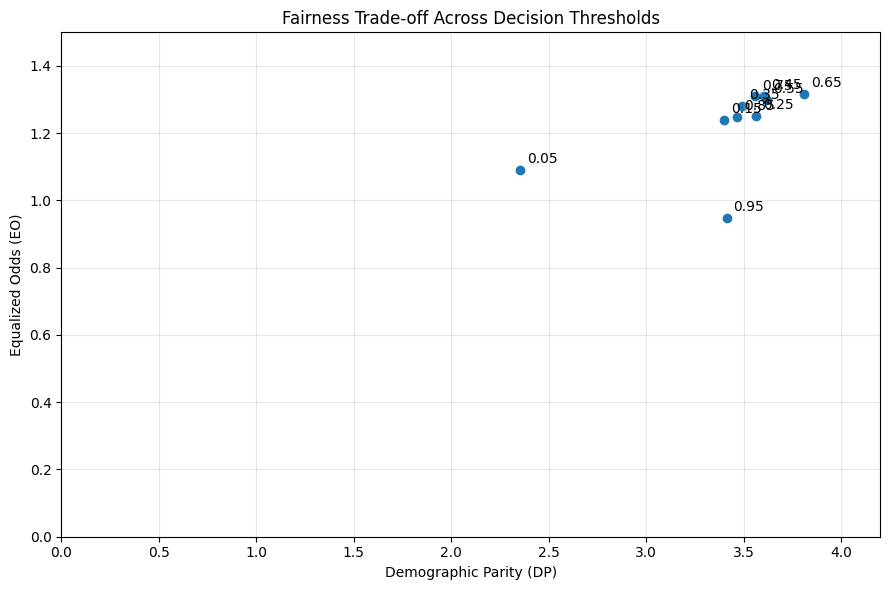

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    fairness_results["DP"],
    fairness_results["EO"]
)

for _, row in fairness_results.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["DP"], row["EO"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Demographic Parity (DP)")
plt.ylabel("Equalized Odds (EO)")
plt.title("Fairness Trade-off Across Decision Thresholds")
plt.xlim(0, 4.2)
plt.ylim(0, 1.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

t_low = fairness_results.loc[
    fairness_results["Threshold"] == 0.05
].iloc[0]

t_high = fairness_results.loc[
    fairness_results["Threshold"] == 0.95
].iloc[0]

dp_change = (t_high["DP"] - t_low["DP"]) / t_low["DP"] * 100

eo_dev_low = abs(t_low["EO"] - 1)
eo_dev_high = abs(t_high["EO"] - 1)

eo_deviation_reduction = (
    (eo_dev_low - eo_dev_high) / eo_dev_low * 100
)

print("DP at threshold 0.05:", round(t_low["DP"], 3))
print("DP at threshold 0.95:", round(t_high["DP"], 3))
print("Percentage increase in DP ratio:", round(dp_change, 2), "%")

print("\nEO at threshold 0.05:", round(t_low["EO"], 3))
print("EO at threshold 0.95:", round(t_high["EO"], 3))
print("Reduction in EO distance from ideal:",
      round(eo_deviation_reduction, 2), "%")


DP at threshold 0.05: 2.354
DP at threshold 0.95: 3.413
Percentage increase in DP ratio: 44.95 %

EO at threshold 0.05: 1.089
EO at threshold 0.95: 0.948
Reduction in EO distance from ideal: 42.31 %
